In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/muhammadaammartufail/global-e-commerce-sales-and-customer-data/global_ecommerce_sales.csv


In [2]:
#EXTRACT

data = pd.read_csv("/kaggle/input/datasets/muhammadaammartufail/global-e-commerce-sales-and-customer-data/global_ecommerce_sales.csv")

print(data.shape)
print("\n")
print(data.info())
print("\n")
print(data.head())
print("\n")
print(data.describe())

(2000, 15)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2000 non-null   object 
 1   Order_Date        2000 non-null   object 
 2   Customer_Name     2000 non-null   object 
 3   Customer_Segment  2000 non-null   object 
 4   Country           2000 non-null   object 
 5   Region            2000 non-null   object 
 6   Product_Category  2000 non-null   object 
 7   Product_Name      2000 non-null   object 
 8   Quantity          2000 non-null   int64  
 9   Unit_Price        2000 non-null   float64
 10  Discount_Percent  2000 non-null   int64  
 11  Total_Sales       2000 non-null   float64
 12  Shipping_Cost     2000 non-null   float64
 13  Profit            2000 non-null   float64
 14  Payment_Method    2000 non-null   object 
dtypes: float64(4), int64(2), object(9)
memory usage: 234.5+ KB
None


    Order_

In [3]:
# TRANSFORM

data["Order_Date"] = pd.to_datetime(data["Order_Date"], errors="coerce")

print(data.dtypes)

Order_ID                    object
Order_Date          datetime64[ns]
Customer_Name               object
Customer_Segment            object
Country                     object
Region                      object
Product_Category            object
Product_Name                object
Quantity                     int64
Unit_Price                 float64
Discount_Percent             int64
Total_Sales                float64
Shipping_Cost              float64
Profit                     float64
Payment_Method              object
dtype: object


In [4]:
#LOAD

import sqlite3
conn = sqlite3.connect("ecom.db")
conn.execute("DROP TABLE IF EXISTS sales;")
data.to_sql("sales", conn, if_exists="replace", index=False)

2000

In [5]:
#QUERY ANALYSIS


# Top 5 countries by revenue
query1 = """
SELECT Country, SUM(Total_Sales) as Revenue
FROM sales
GROUP BY Country
ORDER BY Revenue DESC
LIMIT 5;
"""
print(pd.read_sql(query1, conn))

          Country   Revenue
0          Mexico  47217.30
1          Canada  45326.55
2   United States  41332.53
3           Japan  30950.19
4  United Kingdom  30185.46


In [6]:
# Top 5 customers by revenue
query2 = """
SELECT Customer_Name, SUM(Total_Sales) as Revenue
FROM sales
GROUP BY Customer_Name
ORDER BY Revenue DESC
LIMIT 5;
"""
print(pd.read_sql(query2, conn))

   Customer_Name  Revenue
0  Priya Jackson  3836.46
1    Hanna Jones  3813.98
2     Sarah Chen  3184.56
3     Li Laurent  3007.62
4     Nadia Wang  2958.97


In [7]:
# Monthly sales trend
query3 = """
SELECT strftime('%Y-%m', Order_Date) as Month, SUM(Total_Sales) as Revenue
FROM sales
GROUP BY Month
ORDER BY Month;
"""
print(pd.read_sql(query3, conn))

      Month   Revenue
0   2023-01  11275.20
1   2023-02  16943.67
2   2023-03  16056.45
3   2023-04  12185.00
4   2023-05   8218.47
5   2023-06  16191.61
6   2023-07  15667.73
7   2023-08  12971.07
8   2023-09  11989.72
9   2023-10  17794.60
10  2023-11   8475.49
11  2023-12  16674.44
12  2024-01   8015.21
13  2024-02  11979.60
14  2024-03  10550.11
15  2024-04  15615.06
16  2024-05  16594.20
17  2024-06   9435.15
18  2024-07  14937.53
19  2024-08   9883.83
20  2024-09   9636.38
21  2024-10  17426.05
22  2024-11  16413.27
23  2024-12  14664.34
24  2025-01  12321.18
25  2025-02   7337.28
26  2025-03   7772.33
27  2025-04  16403.60
28  2025-05  17621.80
29  2025-06  18068.09
30  2025-07  15065.96
31  2025-08  11302.11
32  2025-09  14375.95
33  2025-10  15874.75
34  2025-11  14781.02
35  2025-12  14041.09


In [8]:
# Profit by region
query4 = """
SELECT Region, SUM(Profit) as Total_Profit
FROM sales
GROUP BY Region
ORDER BY Total_Profit DESC;
"""
print(pd.read_sql(query4, conn))

                 Region  Total_Profit
0                Europe      45672.16
1         North America      45250.09
2          Asia Pacific      39116.61
3         South America      14680.98
4  Middle East & Africa      14152.48


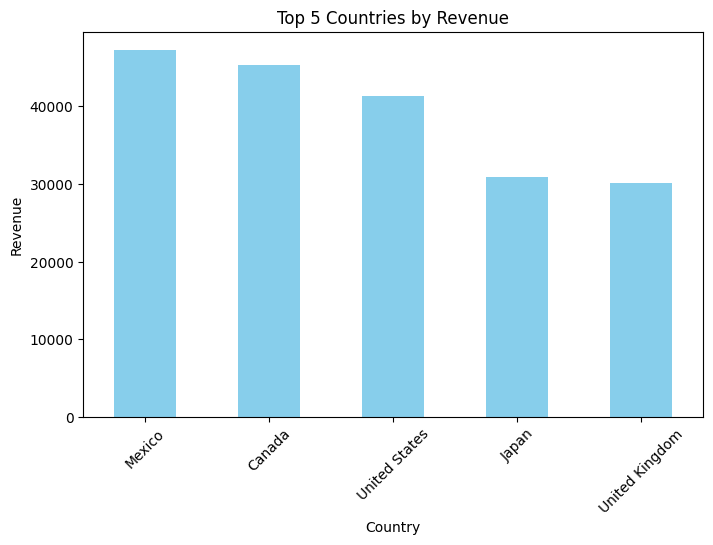

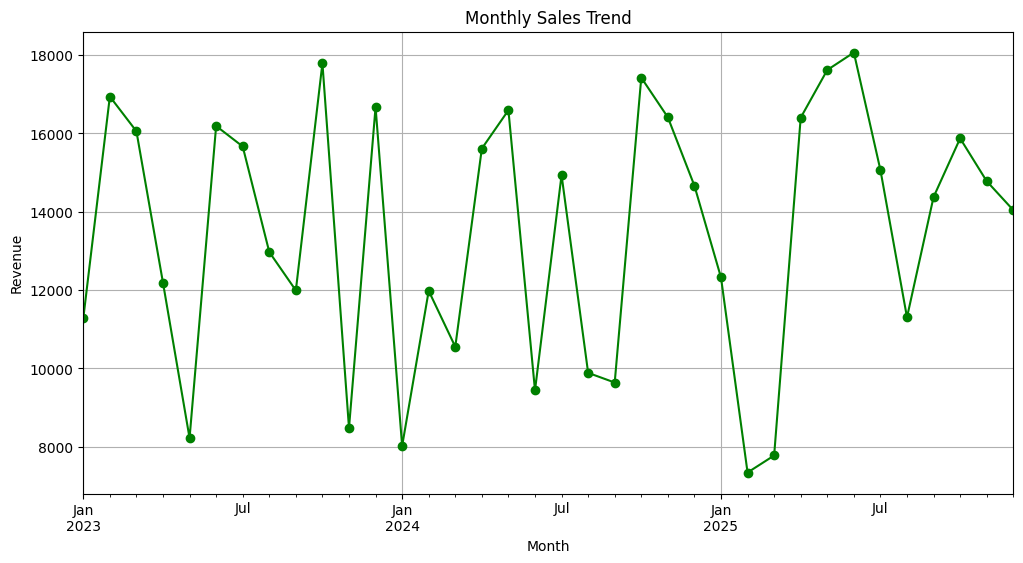

In [9]:
# A BarChart Visualization for query1

import matplotlib.pyplot as plt

top_countries = data.groupby("Country")["Total_Sales"].sum().sort_values(ascending=False).head(5)

plt.figure(figsize=(8,5))
top_countries.plot(kind="bar", color="skyblue")
plt.title("Top 5 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()


# Line chart: Monthly sales trend

monthly_sales = data.groupby(data["Order_Date"].dt.to_period("M"))["Total_Sales"].sum()

plt.figure(figsize=(12,6))
monthly_sales.plot(kind="line", marker="o", color="green")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True)
plt.show()